# EDS 220 HW4 Task 2: Visualizing fire scars through false color
### Author: Sophia Soriano
### GitHub Repository: https://github.com/ssoriano22/eds220-hwk4

## About

Each notebook must include an “About” section with the following subsections:
Purpose: what is this notebook about?
Highlights: List of highlights of analysis (3 or 4 highlights). What do you consider to be the most important aspects of this coding exercise?
About the data: Datasets description
References: Formal references to datasets. You can use the APA style as outlined here.

## Section 2: Fire perimeter data exploration

Explore the fire perimeter data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include, at least, the CRS of the data and whether this is projected or geographic.

In [1]:
# Load packages
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import rioxarray as rioxr

In [2]:
# Load fire perimeter data - Eaton and Palisades shapefile
fp = os.path.join('data','California_Historic_Fire_Perimeters_7724575715026190580','California_Fire_Perimeters_(1950+).shp')
fire_perimeter = gpd.read_file(fp)

# Filter to 2025 only
fire_perimeter = fire_perimeter[fire_perimeter['YEAR_'] == 2025]

# Confirm load (should be 2 rows)
fire_perimeter

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,ALARM_DATE,CONT_DATE,CAUSE,C_METHOD,OBJECTIVE,GIS_ACRES,COMMENTS,COMPLEX_NA,IRWINID,FIRE_NUM,COMPLEX_ID,DECADES,geometry
0,2025,CA,CDF,LDF,PALISADES,00000738,2025-01-07,2025-01-31,14,7,1,23448.9,None,None,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},None,None,2020-2025,"MULTIPOLYGON (((-13193558.265 4032826.468, -13..."
1,2025,CA,CDF,LAC,EATON,00009087,2025-01-08,2025-01-31,14,7,1,14056.3,None,None,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},None,None,2020-2025,"MULTIPOLYGON (((-13146936.686 4051222.067, -13..."


In [3]:
# Display fire_perimeter column info (type and non-null counts)
fire_perimeter.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 2 entries, 0 to 1
Data columns (total 19 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   YEAR_       2 non-null      int64   
 1   STATE       2 non-null      object  
 2   AGENCY      2 non-null      object  
 3   UNIT_ID     2 non-null      object  
 4   FIRE_NAME   2 non-null      object  
 5   INC_NUM     2 non-null      object  
 6   ALARM_DATE  2 non-null      object  
 7   CONT_DATE   2 non-null      object  
 8   CAUSE       2 non-null      int64   
 9   C_METHOD    2 non-null      int64   
 10  OBJECTIVE   2 non-null      int64   
 11  GIS_ACRES   2 non-null      float64 
 12  COMMENTS    0 non-null      object  
 13  COMPLEX_NA  0 non-null      object  
 14  IRWINID     2 non-null      object  
 15  FIRE_NUM    0 non-null      object  
 16  COMPLEX_ID  0 non-null      object  
 17  DECADES     2 non-null      object  
 18  geometry    2 non-null      geometry
dtypes: float6

In [4]:
# Check types of geometry in fire_perimeter
fire_perimeter.geom_type

0    MultiPolygon
1    MultiPolygon
dtype: object

In [5]:
# Check fire_perimeter crs
fire_perimeter.crs

<Projected CRS: EPSG:3857>
Name: WGS 84 / Pseudo-Mercator
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: World between 85.06°S and 85.06°N.
- bounds: (-180.0, -85.06, 180.0, 85.06)
Coordinate Operation:
- name: Popular Visualisation Pseudo-Mercator
- method: Popular Visualisation Pseudo Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [6]:
# Print specific info from crs
print('Ellipsoid: ', fire_perimeter.crs.ellipsoid)
print('Datum: ', fire_perimeter.crs.datum)
print('Is projected?: ', fire_perimeter.crs.is_projected)

Ellipsoid:  WGS 84
Datum:  World Geodetic System 1984 ensemble
Is projected?:  True


In [7]:
# Display extent of fire_perimeter (minx, miny, maxx, maxy)
print('CALFIRE GeoDataset Extent:')
print('minx:',fire_perimeter.total_bounds[0])
print('miny:',fire_perimeter.total_bounds[1])
print('maxx:',fire_perimeter.total_bounds[2])
print('maxy:',fire_perimeter.total_bounds[3])

CALFIRE GeoDataset Extent:
minx: -13212050.788800001
miny: 4032810.7585000023
maxx: -13137152.8556
maxy: 4060781.9439999983


This dataset containing fire perimeter polygon and multipolygon geometries for the 2025 Eaton and Palisades fires in California was downloaded from the CALFIRE geodata portal mentioned in the citation below. The dataset has 18 columns with 2 rows, one for the 2025 Eaton fire perimeter and one for the 2025 Palisades fire perimeter. The data used a projected 2D crs - EPSG:3857 - with an extent (metres) of minx: -13212050.7888, miny: 4032810.7585, maxx: -13137152.8556, maxy: 4060781.9440. The following columns have no data in either row: COMMENTS, COMPLEX_NA, FIRE_NUM, COMPLEX_ID.

CALFIRE Eaton and Palisades 2025 Shapefile Citation: California Department of Forestry and Fire Protection. (2026). California fire perimeters (1950+) (Version firep25_1) [Data set]. California State Geoportal. https://gis.data.ca.gov/maps/c3c10388e3b24cec8a954ba10458039d/about

## Section 3: NetCDF data import and exploration

a) Import the Landsat data using xr.open_dataset().

b) Explore the data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include a description of the data’s variables, dimensions, and coordinates.



In [8]:
# Load landsat data as matrix (xr.open_dataaset())
fp2 = os.path.join('data','landsat8-2025-02-23-palisades-eaton.nc')
landsat = xr.open_dataset(fp2)
landsat

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

The landsat dataset has two dimensions - x with a size of 1418 and y with a size of 2742 - and three coordinates - y, x, and time. The landsat dataset variables correspond to the bands measured by the Landsat8 satellite - red, green, blue, nir08 (near infrared), swir22 (short wavelength infrared), and spatial_ref. The spatial_ref variable contains metadata describing this dataset. The projected 2D crs used is noted to be EPSG:32611 in the WKT above, and the units for projected 2D crs are expected to be meters.

Landsat Data Citation: U.S. Geological Survey. (2025). Landsat 8–9 OLI/TIRS Collection 2 Level-2 science products [Data set]. Microsoft Planetary Computer. https://doi.org/10.5066/P9OGBGM6. Retrieved from EDS220 Google Drive: https://drive.google.com/drive/folders/1USqhiMLyN8GE05B8WJmHabviJGnmAsLP

## Section 4: Restoring geospatial information

a) Use rio.crs to print the CRS of this dataset. Is this a geospatial object?

b) You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable spatial_ref. Print the CRS by accessing the spatial_ref.crs_wkt attribute of the dataset.

c) Recover the geospatial information by using rio.write_crs() and the spatial reference information from part b.

d) Print the CRS of the updated dataset.

In [9]:
# Display landsat crs using rio.crs
print("Landsat Dataset CRS:",landsat.rio.crs)

Landsat Dataset CRS: None


Trying to display the rio.crs attribute returns `None`, suggesting that the landsat dataset is not currently a geospatial object since it has no assigned CRS. Geospatial data is currently written in the WKT in the spatial_ref variable of the landsat dataset.

In [10]:
# Display landsat crs wkt
print("Landsat CRS WKT:",landsat['spatial_ref'].attrs['crs_wkt'])

# Assign the final AUTHORITY[] EPSG to be the landsat crs using rio.write_crs()
landsat = landsat.rio.write_crs("EPSG:32611")

# Confirm crs update
print("Fixed Landsat CRS:",landsat.rio.crs)


Landsat CRS WKT: PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]
Fixed Landsat CRS: EPSG:32611


The Landsat CRS was viewable in the crs_wkt attribute in the spatial_ref variable of the dataset, but it was not accessible using rioxarray. The rio.write_crs() function was used to manually add the final EPSG code in the spatial_ref crs_wkt (EPSG:32611) as the rio.crs attribute. This fix is confirmed in the print statment above.

## Section 5: True color image

a) Without creating any new variables:
- select the red, green, and blue variables (in that order) of the xarray.Dataset holding the Landsat data,
- convert it to an xarray.DataArray using the to_dataarray() method, and then
- use .plot.imshow() to create an RGB image with the data. There will be a warning; that’s ok.

b) Adjust the scale used for plotting the bands to get a true color image. HINT: Check the robust parameter.

c) To resolve the other warning, identify which bands have nan values. HINT: There are many ways of doing so. One option is to use numpy.isnan().

d) Use the .fillna() method for xarray.Datasets to replace any nan values in the Landsat data with zero.

e) Create a new true color image that gets plotted without warnings.

f) In a markdown cell write a brief explanation comparing the outputs for parts (a) and (e).

In [11]:
# Access r, g, b band variables, convert to dataarray, and plot
landsat[["red","green","blue"]].to_dataarray().plot.imshow()


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


/Users/smsoriano/miniforge3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


/Users/smsoriano/miniforge3/envs/eds220-env/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


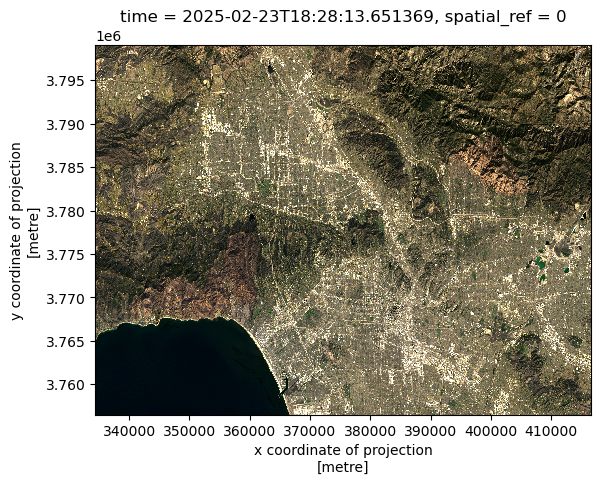

In [12]:
# Add the 'robust = True' argument:
#   Stretches the color scale to lessen the effect of extreme min and max pixel values
landsat[["red","green","blue"]].to_dataarray().plot.imshow(robust = True)

In [13]:
# Determine how many nan values in each band of landsat
np.isnan(landsat).sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 1
    blue         int64 8B 109
    nir08        int64 8B 0
    swir22       int64 8B 0

In [14]:
# Use fillna() to replace nans found above
landsat_fill = landsat.fillna(0)

# Confirm fillna() worked
np.isnan(landsat_fill).sum()

<xarray.Dataset> Size: 56B
Dimensions:      ()
Coordinates:
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          int64 8B 0
    green        int64 8B 0
    blue         int64 8B 0
    nir08        int64 8B 0
    swir22       int64 8B 0

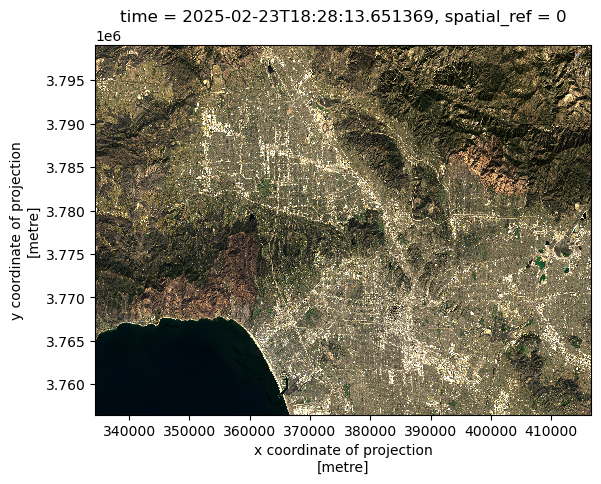

In [15]:
# Re-generate rgb image w/o nans
landsat_fill[["red","green","blue"]].to_dataarray().plot.imshow(robust = True)

A message and a warning resulted from initially attempting to plot the Landsat RGB array in step a, which only produced a white plot with projection axes and a timestamp title. The message stated that the imshow() method clipped the input landsat array data into a valid RGB range, which suggests that some band/variable data was not within the RGB range expected (0-255). Similarly, the warning mentioned that an "invalid value" was encounted while trying to change data types to perform int8 math. To address these issues, the 'robust = true' parameter was added to the imshow() method in order to stretch the data's RGB color values across the possible RGB range. Also, NaN values were discovered in the green (1) and blue (109) bands being plotted. These NaN values were filled with zeros, and the resulting `landsat_fill` dataset RGB bands were again transformed into an array and plotted in step e. This new image clearly displays an area in Los Angeles (LA) in true color, with two browner areas that likely correspond to the Eaton and Palisades fires.

## Section 6: False color image

Without creating any new variables, create a false color image by plotting the shortwave infrared (swir22), near-infrared, and red variables (in that order)

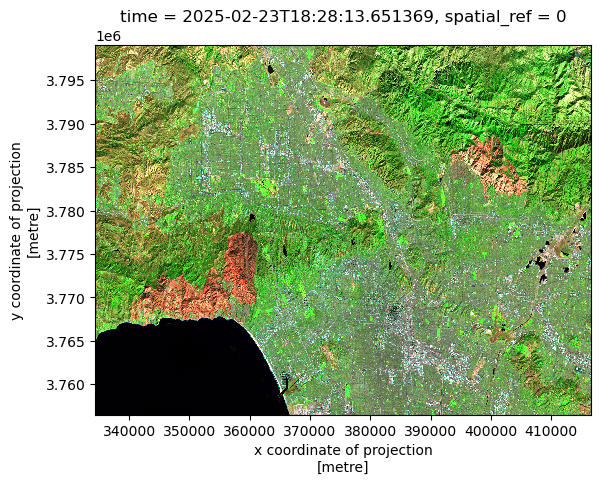

In [16]:
# Generate false color image using "swir22","nir08","red" bands/variables
landsat_fill[["swir22","nir08","red"]].to_dataarray().plot.imshow(robust = True)

The false color image above was generated using the following bands from the `landsat_fill` dataset: "swir22", "nir08", "red". Since there were no Nan values found in any of these bands, no zeros were imputed. This band combination is often used in remote sensing to visualize burn scars appearing in landscapes. Two orange areas are clear in this false color image, corresponding to the brown areas described above in the true color image of the same LA area.

## Section 7: Map

a) Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire perimeters. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

b) Write a figure description for the map including a brief explanation of how false color imagery is being used.

In [ ]:
# Check if CRS currently match (likely not yet)
print("CALFIRE CRS:", fire_perimeter.crs)
print("Landsat CRS:", landsat_fill.rio.crs)

CALFIRE CRS: EPSG:3857
Landsat CRS: EPSG:32611


In [31]:
# Reproject fire_perimeter CRS to match Landsat EPSG:32611
#   Manually written to avoid getting entire wkt
fire_perimeter = fire_perimeter.to_crs("EPSG:32611")

# Check if CRS currently match (now they should)
print("CALFIRE CRS:", fire_perimeter.crs)
print("Landsat CRS:", landsat_fill.rio.crs)

assert fire_perimeter.crs == landsat_fill.rio.crs

CALFIRE CRS: EPSG:32611
Landsat CRS: EPSG:32611


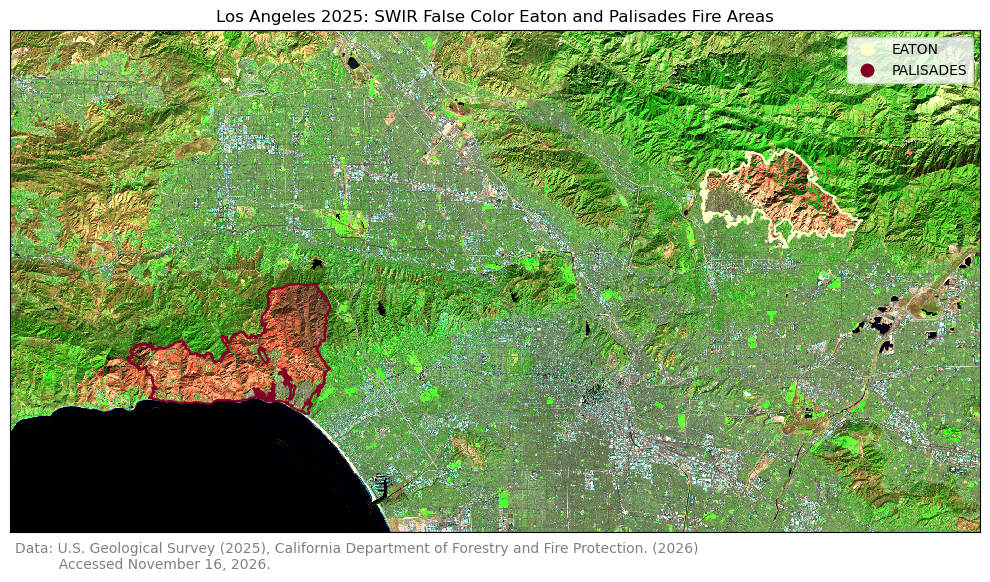

In [75]:
## DATA VISUALIZATION

# Initialize empty figure
fig, ax = plt.subplots(figsize = (10,8))

# Add landsat raster data to ax
landsat_fill[["swir22","nir08","red"]].to_dataarray().plot.imshow(
      ax = ax,
      # Stretch rgb
      robust = True,
      # Remove axes labels
      add_labels = False
)

# Add fire_perimeter vector data to ax
fire_perimeter.plot(ax = ax,
                  # Only keep borders
                  facecolor = "none",
                  # Color border by fire
                  column = "FIRE_NAME",
                  # Sepcify colors
                  cmap="YlOrRd",
                  # Set line width
                  linewidth=1.5,
                  # Display legend
                  legend = True,
                  # Specify legend location
                  legend_kwds={"loc": "upper right"}
)

# Set title
ax.set_title("Los Angeles 2025: SWIR False Color Eaton and Palisades Fire Areas")

# Remove xticks and yticks
ax.set_xticks([])
ax.set_yticks([])

# Add data caption
plt.figtext(0.02, 0.14,"Data: U.S. Geological Survey (2025), California Department of Forestry and Fire Protection. (2026) \n          Accessed November 16, 2026.", color = "grey")

# Display figure
plt.tight_layout()
plt.show()

Figure 1: The false color image above was generated using the following bands from the Landsat dataset: "swir22", "nir08", "red" (U.S. Geological Survey 2025). This band combination is often used in remote sensing to visualize burn scars appearing in landscapes, as the SWIR band - in the red channel - detects moisture and heat, the NIR band - in the green channel - detects vegetation - and the red band - in the blue channel - shows land types that reflect red light (i.e. ocean is very dark because it absorbs red light). Two orange areas denoting burn scars are clear in this false color image. Each area corresponds to a recorded fire perimeter, shown in either light yellow for the Eaton fire or in dark red for the Palisades fire (California Department of Forestry and Fire Protection 2026).